# Alquiler — 01 EDA

Exploración de los alquileres de Moscú para un modelo de regresión lineal
de `monthly_rent_rub`.

- **Fase A**: `rentals.csv` solo (univariado, bivariado, correlación, normalidad).
- **Fase B**: joins con `district_prices_monthly.csv` y `metro_stations.csv`
  (contexto distrital-mensual, series, metro).

## 0. Entorno

Correr con el kernel **(.venv)**. Si falta el entorno:

```
source .venv/bin/activate
pip install -r requirements.txt
```

In [71]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

DATA_DIR = Path("..") / "data"
TARGET = "monthly_rent_rub"
RNG = np.random.default_rng(42)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

print("pandas", pd.__version__, "| numpy", np.__version__)
print("DATA_DIR:", DATA_DIR.resolve(), "| existe:", DATA_DIR.exists())

pandas 3.0.6 | numpy 2.5.4
DATA_DIR: /Users/tomasmontilla/workspace/facultad/Moscow-real-estate-market--Sales-and-rentals/data | existe: True


## Fase A — rentals.csv solo

### A.1 Carga

In [72]:
rentals = pd.read_csv(DATA_DIR / "rentals.csv")
print(f"{len(rentals):,} filas x {rentals.shape[1]} columnas")
display(rentals.head())
display(rentals.dtypes.astype(str).rename("dtype").to_frame())

20,000 filas x 22 columnas


,id,date_posted,district,okrug,lat,lon,total_area,rooms,floor,total_floors,building_year,building_type,renovation,furnished,pets_allowed,deposit_months,metro_station,metro_line,metro_distance_min,to_center_km,monthly_rent_rub,rent_per_sqm
0,R000001,2025-01-16,Nagatinsky Zaton,YuAO,55.70058,37.69344,34.7,1,5,9,1958,brick,cosmetic,False,True,1,Ugreshskaya,MCC,28,7.47,26200,756
1,R000002,2022-11-12,Chertanovo Severnoye,YuAO,55.64717,37.61690,53.4,1,10,12,2010,monolith,cosmetic,True,False,1,Kuznetsky Most,Tagansko-Krasnopresnenskaya,152,11.87,37200,696
2,R000003,2026-03-06,Savyolovsky,SAO,55.78584,37.57104,69.9,2,15,22,2009,monolith,euro,True,False,1,Rizhskaya,Kaluzhsko-Rizhskaya,43,4.72,96700,1384
3,R000004,2024-10-11,Beskudnikovsky,SAO,55.87034,37.56080,44.6,2,14,17,1980,brick,no_renovation,True,False,1,Trubnaya,Lyublinsko-Dmitrovskaya,145,13.48,30200,677
4,R000005,2023-07-11,Shchapovskoye,TAO,55.37723,37.51217,56.7,1,3,5,1979,panel,euro,False,False,1,Dubrovka,Lyublinsko-Dmitrovskaya,472,42.44,18700,330


,dtype
id,str
date_posted,str
district,str
okrug,str
lat,float64
lon,float64
total_area,float64
rooms,int64
floor,int64
total_floors,int64


#### Diccionario de datos (rentals.csv + derivadas)

In [73]:
DIC = [
    ("id", "identificador", "ID unico del aviso"),
    ("date_posted", "fecha de publicacion",
     "Fecha de publicacion del aviso (YYYY-MM-DD)"),
    ("district", "distrito", "Distrito de Moscu (129 valores)"),
    ("okrug", "okrug",
     "Agrupacion de distritos (11 valores: CAO, ZAO, ...)"),
    ("lat", "latitud", "Latitud del inmueble"),
    ("lon", "longitud", "Longitud del inmueble"),
    ("total_area", "superficie total (m2)",
     "Superficie total en metros cuadrados"),
    ("rooms", "ambientes", "Cantidad de ambientes (1 a 4)"),
    ("floor", "piso", "Piso del departamento"),
    ("total_floors", "pisos del edificio",
     "Cantidad de pisos del edificio"),
    ("building_year", "anio de construccion",
     "Anio de construccion del edificio"),
    ("building_type", "tipo de edificio",
     "brick, panel, monolith, stalin, khrushchev, modern_panel"),
    ("renovation", "renovacion",
     "no_renovation, cosmetic, euro, designer"),
    ("furnished", "amueblado",
     "True/False: el aviso incluye muebles"),
    ("pets_allowed", "mascotas permitidas",
     "True/False: acepta mascotas"),
    ("deposit_months", "meses de deposito",
     "Meses de alquiler pedidos como deposito (0 a 2)"),
    ("metro_station", "estacion de metro",
     "Estacion mas cercana (104 valores)"),
    ("metro_line", "linea de metro",
     "Linea de la estacion mas cercana"),
    ("metro_distance_min", "distancia al metro",
     "Distancia a la estacion (rango 0-966)"),
    ("to_center_km", "distancia al centro (km)",
     "Distancia al centro de Moscu en km"),
    ("monthly_rent_rub", "alquiler mensual (RUB)",
     "VARIABLE TARGET del modelo"),
    ("rent_per_sqm", "alquiler por m2",
     "Deriva del target: NO usar como feature (fuga)"),
    ("year_month", "mes YYYY-MM (derivada)",
     "Derivada de date_posted para joins con el mensual"),
    ("log_rent", "log del alquiler (derivada)",
     "log1p del target: version simetrica para modelar"),
]
dic = pd.DataFrame(DIC, columns=["columna", "traduccion", "descripcion"])
display(dic)
sin_doc = sorted(set(rentals.columns) - set(dic["columna"]))
print("columnas crudas sin documentar:",
      sin_doc if sin_doc else "ninguna")

,columna,traduccion,descripcion
0,id,identificador,ID unico del aviso
1,date_posted,fecha de publicacion,Fecha de publicacion del aviso (YYYY-MM-DD)
2,district,distrito,Distrito de Moscu (129 valores)
3,okrug,okrug,"Agrupacion de distritos (11 valores: CAO, ZAO,..."
4,lat,latitud,Latitud del inmueble
5,lon,longitud,Longitud del inmueble
6,total_area,superficie total (m2),Superficie total en metros cuadrados
7,rooms,ambientes,Cantidad de ambientes (1 a 4)
8,floor,piso,Piso del departamento
9,total_floors,pisos del edificio,Cantidad de pisos del edificio


columnas crudas sin documentar: ninguna


### A.2 Estructura, nulos y duplicados

In [74]:
rows = []
for col in rentals.columns:
    s = rentals[col]
    rows.append({"columna": col, "dtype": str(s.dtype),
                 "n_nulos": int(s.isna().sum()),
                 "pct_nulos": round(100 * s.isna().mean(), 2),
                 "n_unicos": int(s.nunique())})
display(pd.DataFrame(rows))
print("filas duplicadas completas:", int(rentals.duplicated().sum()))

,columna,dtype,n_nulos,pct_nulos,n_unicos
0,id,str,0,0.0,20000
1,date_posted,str,0,0.0,1945
2,district,str,0,0.0,129
3,okrug,str,0,0.0,11
4,lat,float64,0,0.0,15985
5,lon,float64,0,0.0,16678
6,total_area,float64,0,0.0,695
7,rooms,int64,0,0.0,4
8,floor,int64,0,0.0,22
9,total_floors,int64,0,0.0,5


filas duplicadas completas: 0


In [75]:
miss = rentals.isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0]
if miss.empty:
    print("Sin valores nulos en rentals.csv")
else:
    fig, ax = plt.subplots(figsize=(7, max(2, 0.4 * len(miss))))
    miss.sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_xlabel("% nulos")
    ax.set_title("Nulos por columna")
    plt.tight_layout()
    plt.show()

Sin valores nulos en rentals.csv


### A.3 Univariado numérico: centro, dispersión y sesgo

In [76]:
num = rentals.select_dtypes(include=np.number)
desc = num.describe().T
desc["skew"] = num.skew().round(3)
desc["kurtosis"] = num.kurtosis().round(3)


def tag_skew(v):
    a = abs(v)
    if a <= 0.5:
        return "simetrico"
    if a <= 1.0:
        return "sesgo moderado"
    return "muy sesgado"


desc["lectura_skew"] = desc["skew"].map(tag_skew)
display(desc.round(3))
print("Regla: |skew|<=0.5 simetrico; 0.5-1 moderado; >1 muy sesgado.")

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,lectura_skew
lat,20000.0,55.713,0.144,55.230,55.636,55.740,55.818,56.013,-0.980,0.908,sesgo moderado
lon,20000.0,37.542,0.181,36.702,37.465,37.564,37.652,37.908,-1.224,2.969,muy sesgado
total_area,20000.0,55.387,12.740,22.100,45.700,53.800,63.300,104.600,0.577,-0.087,sesgo moderado
rooms,20000.0,1.794,0.865,1.000,1.000,2.000,2.000,4.000,0.847,-0.115,sesgo moderado
floor,20000.0,6.608,4.830,1.000,3.000,5.000,9.000,22.000,1.074,0.619,muy sesgado
total_floors,20000.0,12.191,5.692,5.000,9.000,9.000,17.000,22.000,0.437,-1.034,simetrico
building_year,20000.0,1987.823,22.500,1935.000,1968.000,1988.000,2008.000,2024.000,-0.101,-1.141,simetrico
deposit_months,20000.0,1.101,0.541,0.000,1.000,1.000,1.000,2.000,0.072,0.275,simetrico
metro_distance_min,20000.0,152.385,167.803,0.000,33.000,103.000,198.000,966.000,1.963,4.039,muy sesgado
to_center_km,20000.0,16.360,12.801,0.020,9.040,13.230,18.030,71.060,2.121,4.828,muy sesgado


Regla: |skew|<=0.5 simetrico; 0.5-1 moderado; >1 muy sesgado.


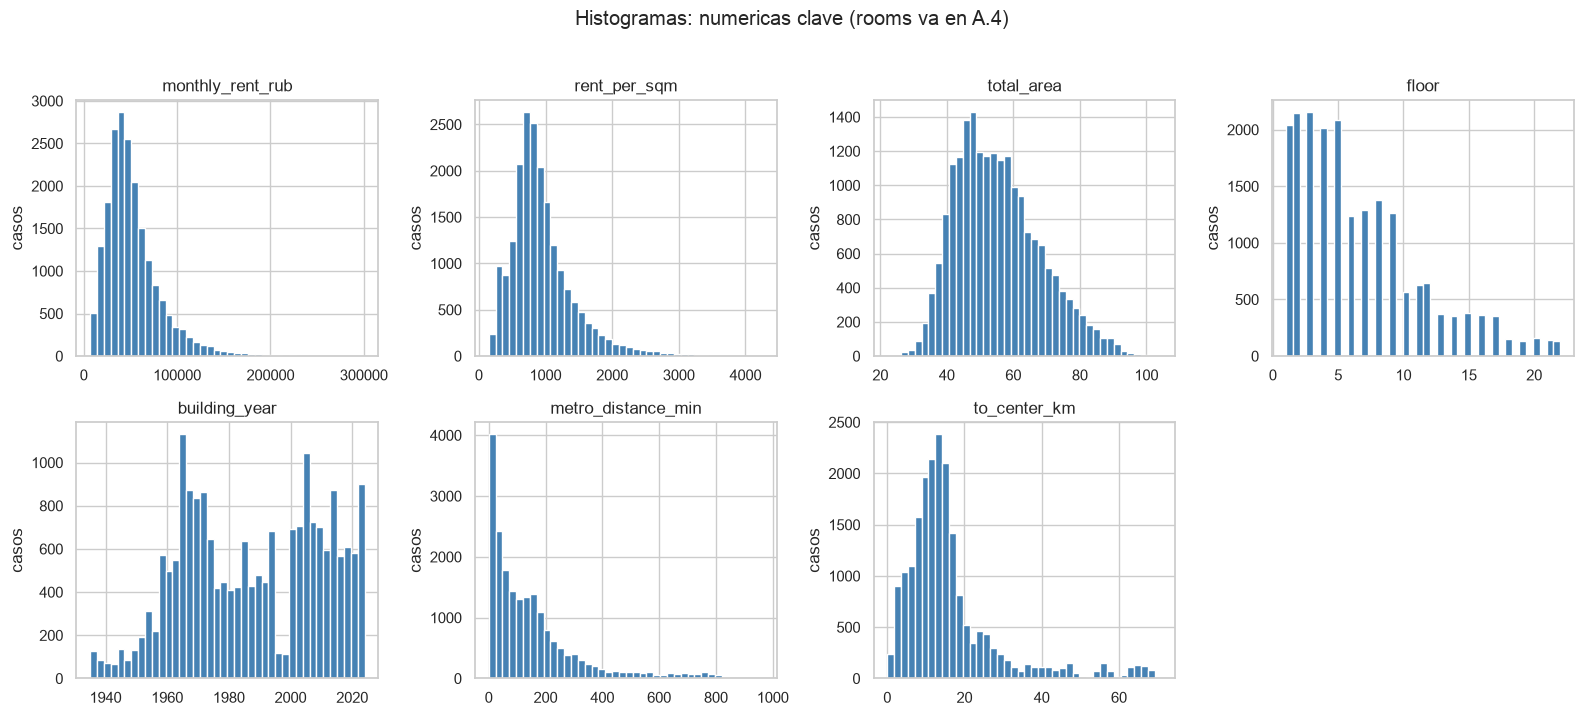

In [77]:
# rooms (4 valores) no va aca: va como barras de conteo en A.4
KEY_NUM = [TARGET, "rent_per_sqm", "total_area", "floor",
           "building_year", "metro_distance_min", "to_center_km"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), KEY_NUM):
    rentals[col].hist(bins=40, ax=ax, color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("casos")
for ax in axes.ravel()[len(KEY_NUM):]:
    ax.axis("off")
plt.suptitle("Histogramas: numericas clave (rooms va en A.4)", y=1.02)
plt.tight_layout()
plt.show()

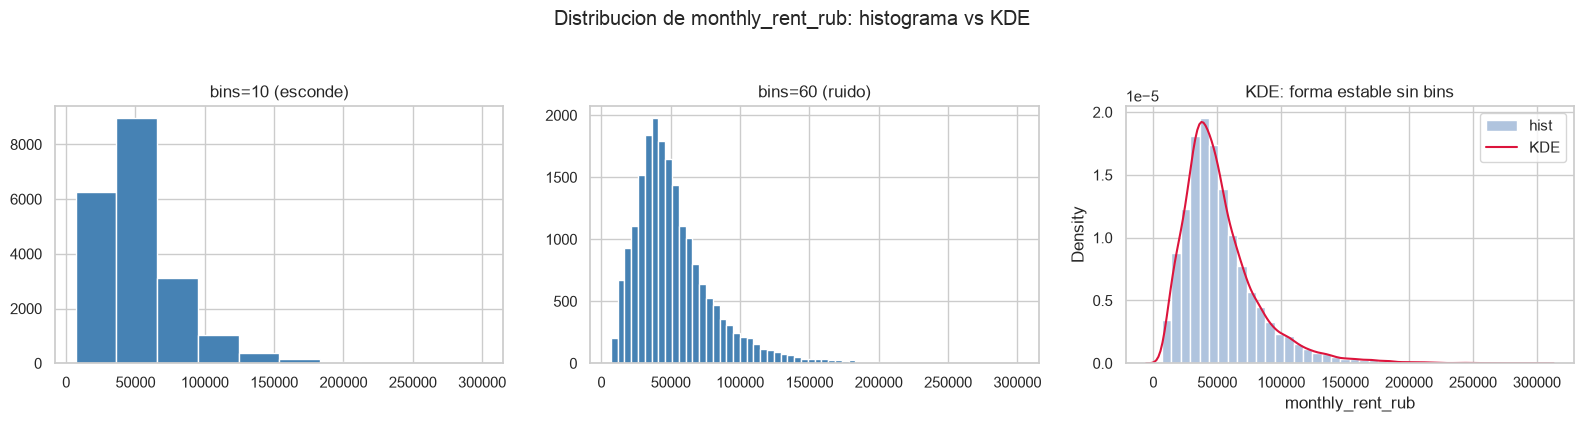

skew: 1.82 (positivo = cola a la derecha, tipico en precios)


In [78]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
x = rentals[TARGET]
axes[0].hist(x, bins=10, color="steelblue", edgecolor="white")
axes[0].set_title("bins=10 (esconde)")
axes[1].hist(x, bins=60, color="steelblue", edgecolor="white")
axes[1].set_title("bins=60 (ruido)")
axes[2].hist(x, bins=40, color="lightsteelblue", edgecolor="white",
             density=True, label="hist")
sns.kdeplot(x=x, ax=axes[2], color="crimson", label="KDE")
axes[2].set_title("KDE: forma estable sin bins")
axes[2].legend()
plt.suptitle(f"Distribucion de {TARGET}: histograma vs KDE", y=1.05)
plt.tight_layout()
plt.show()
print("skew:", round(float(x.skew()), 3),
      "(positivo = cola a la derecha, tipico en precios)")

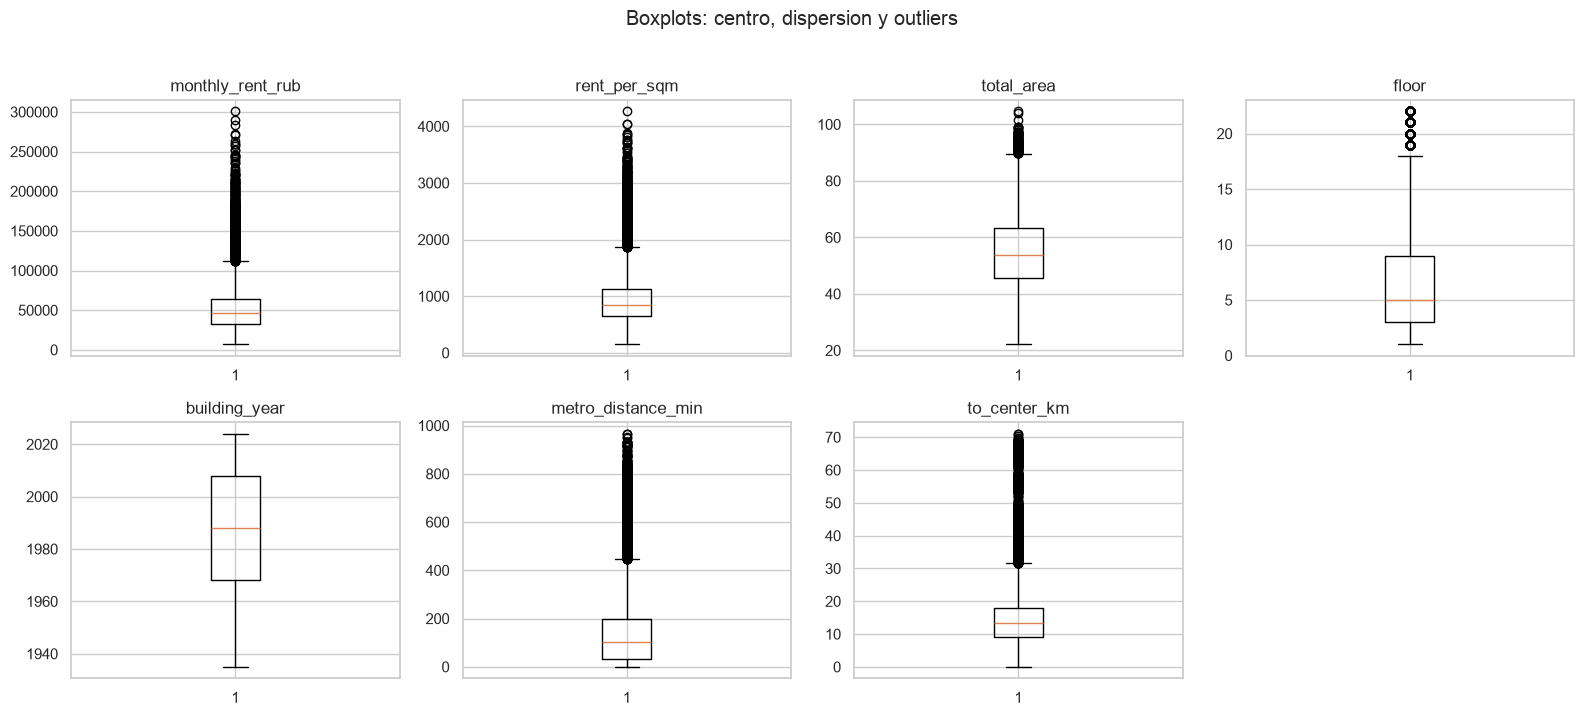

In [79]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), KEY_NUM):
    ax.boxplot(rentals[col].dropna())
    ax.set_title(col)
for ax in axes.ravel()[len(KEY_NUM):]:
    ax.axis("off")
plt.suptitle("Boxplots: centro, dispersion y outliers", y=1.02)
plt.tight_layout()
plt.show()

### A.4 Univariado categorico: conteos con barras

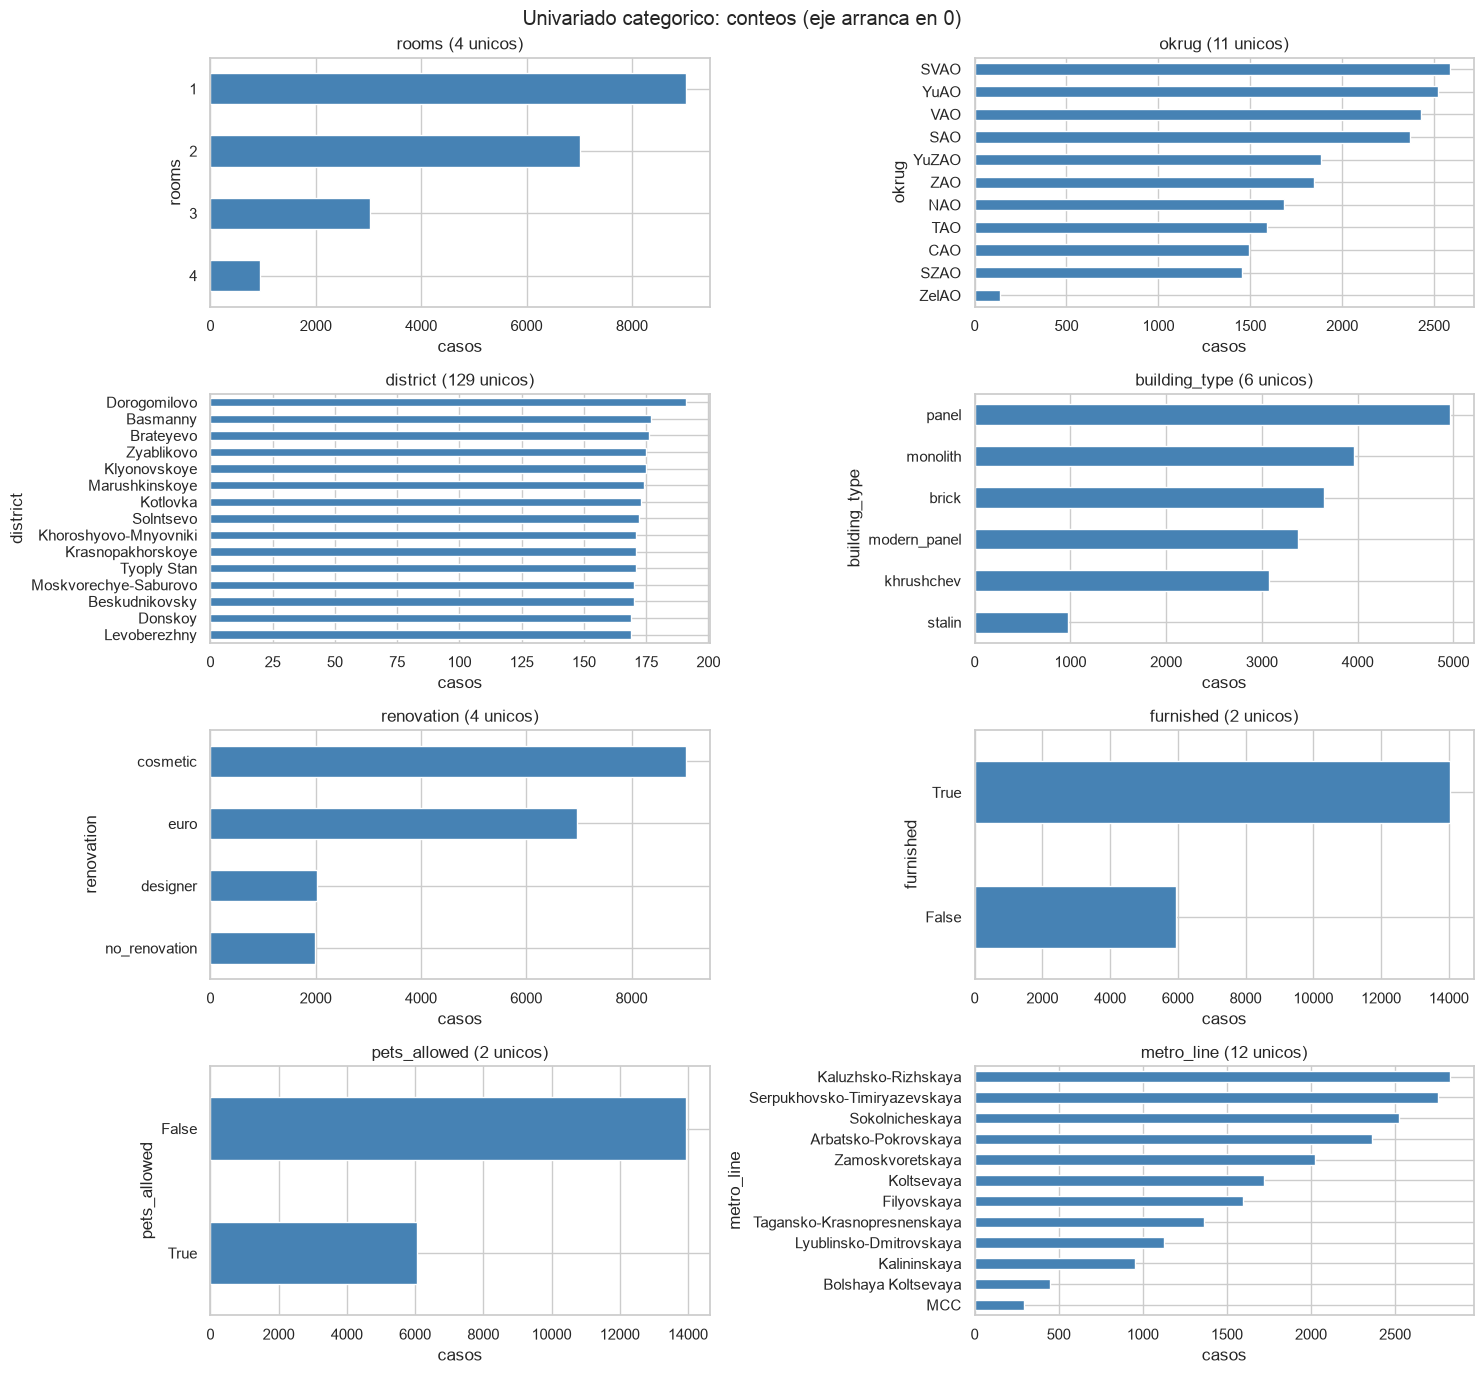

In [80]:
CATS = {"rooms": None, "okrug": None, "district": 15,
        "building_type": None, "renovation": None, "furnished": None,
        "pets_allowed": None, "metro_line": 12}
fig, axes = plt.subplots(4, 2, figsize=(15, 14))
for ax, (col, topn) in zip(axes.ravel(), CATS.items()):
    vc = rentals[col].astype(str).value_counts()
    if topn:
        vc = vc.head(topn)
    vc.sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"{col} ({rentals[col].nunique()} unicos)")
    ax.set_xlabel("casos")
for ax in axes.ravel()[len(CATS):]:
    ax.axis("off")
plt.suptitle("Univariado categorico: conteos (eje arranca en 0)")
plt.tight_layout()
plt.show()

### A.5 Bivariado numerico vs alquiler

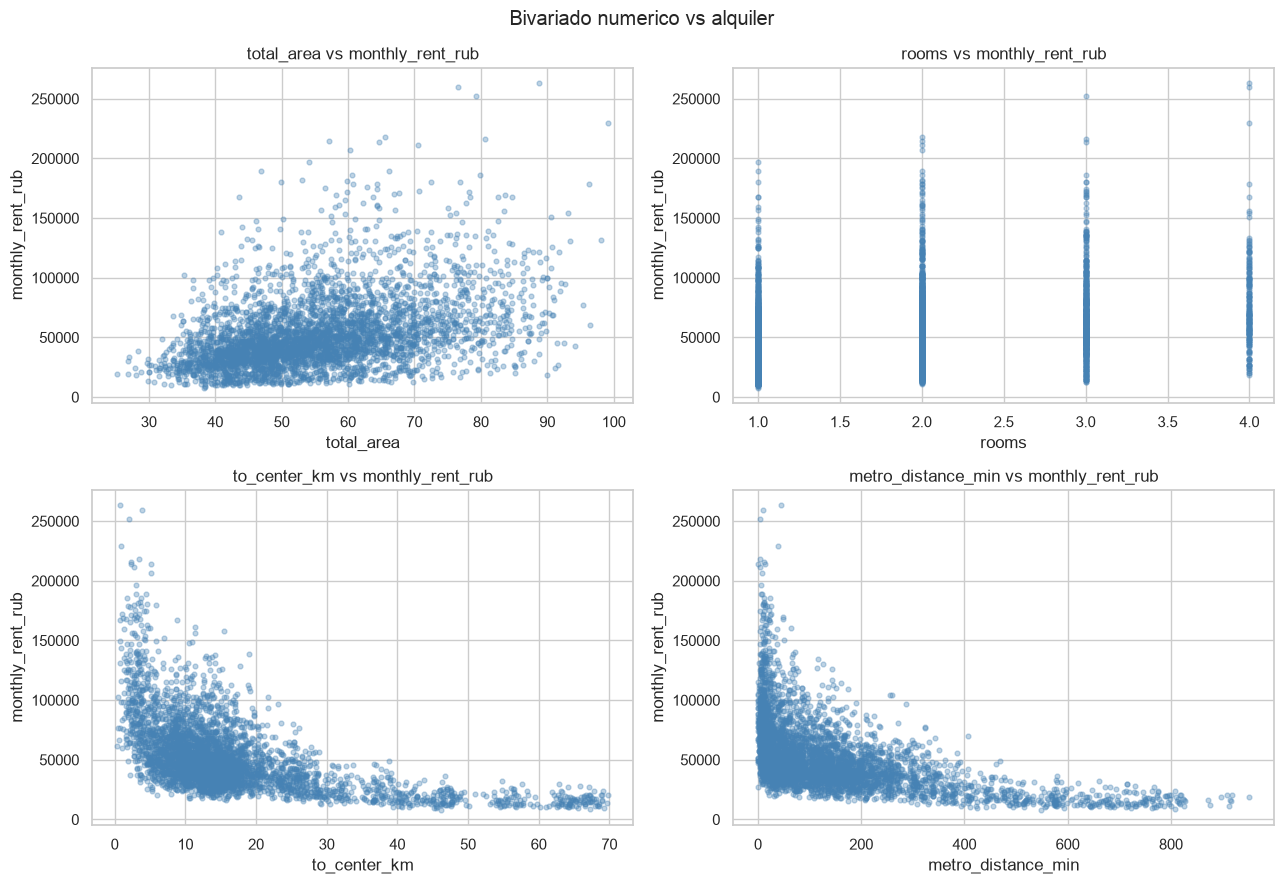

In [81]:
sample = rentals.sample(min(4000, len(rentals)), random_state=42)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ["total_area", "rooms", "to_center_km",
                                  "metro_distance_min"]):
    ax.scatter(sample[col], sample[TARGET], alpha=0.35, s=12,
               color="steelblue")
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)
    ax.set_title(f"{col} vs {TARGET}")
plt.suptitle("Bivariado numerico vs alquiler")
plt.tight_layout()
plt.show()

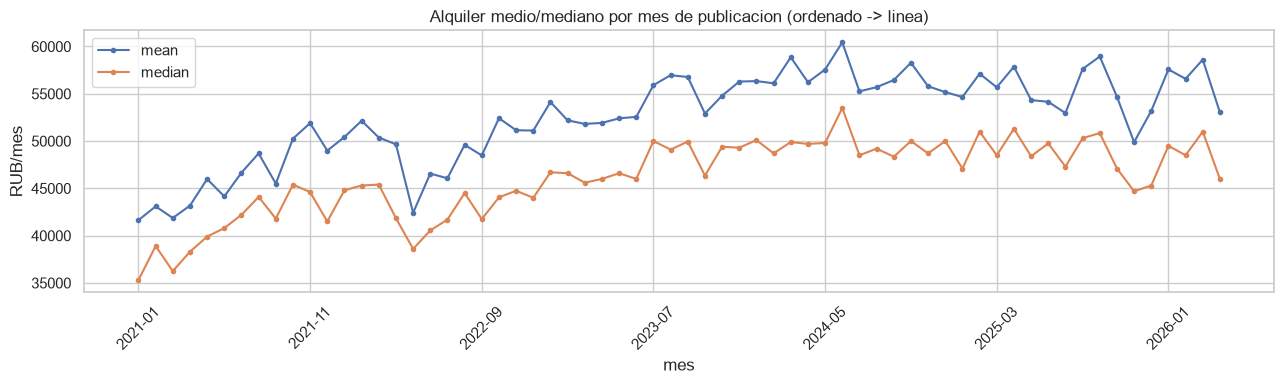

meses: 64 | media > mediana en 64 meses (sesgo a derecha persistente)


In [82]:
rentals["year_month"] = pd.to_datetime(
    rentals["date_posted"]).dt.strftime("%Y-%m")
mensual = rentals.groupby("year_month")[TARGET].agg(["mean", "median",
                                                     "count"])
fig, ax = plt.subplots(figsize=(13, 4))
mensual[["mean", "median"]].plot(ax=ax, marker="o", markersize=3)
ax.set_title("Alquiler medio/mediano por mes de publicacion "
             "(ordenado -> linea)")
ax.set_ylabel("RUB/mes")
ax.set_xlabel("mes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print("meses:", len(mensual), "| media > mediana en",
      int((mensual["mean"] > mensual["median"]).sum()),
      "meses (sesgo a derecha persistente)")

### A.6 Bivariado categorico vs alquiler: agrupar

In [83]:
for col in ["rooms", "building_type", "renovation", "furnished",
            "okrug"]:
    t = (rentals.groupby(col, observed=True)[TARGET]
         .agg(["mean", "median", "count"]).round(0)
         .sort_values("mean", ascending=False))
    print(f"--- {col} ---")
    display(t)

--- rooms ---


,mean,median,count
rooms,,,
4,78454.0,69100.0,945
3,67760.0,60200.0,3020
2,55249.0,49100.0,7008
1,42395.0,37700.0,9027


--- building_type ---


,mean,median,count
building_type,,,
stalin,63958.0,55700.0,975
monolith,57925.0,50600.0,3958
brick,54652.0,48200.0,3650
modern_panel,52888.0,46400.0,3374
panel,48554.0,43100.0,4967
khrushchev,44844.0,39100.0,3076


--- renovation ---


,mean,median,count
renovation,,,
designer,66475.0,57400.0,2021
euro,55912.0,49300.0,6959
cosmetic,48496.0,43000.0,9035
no_renovation,43858.0,38400.0,1985


--- furnished ---


,mean,median,count
furnished,,,
True,53576.0,46900.0,14043
False,49738.0,43400.0,5957


--- okrug ---


,mean,median,count
okrug,,,
CAO,110537.0,103100.0,1493
ZAO,64829.0,60100.0,1849
YuZAO,64735.0,59800.0,1887
SZAO,61641.0,56100.0,1456
SAO,51185.0,47200.0,2367
VAO,47534.0,44000.0,2431
YuAO,45497.0,42300.0,2520
SVAO,45123.0,42200.0,2588
NAO,30922.0,29450.0,1682


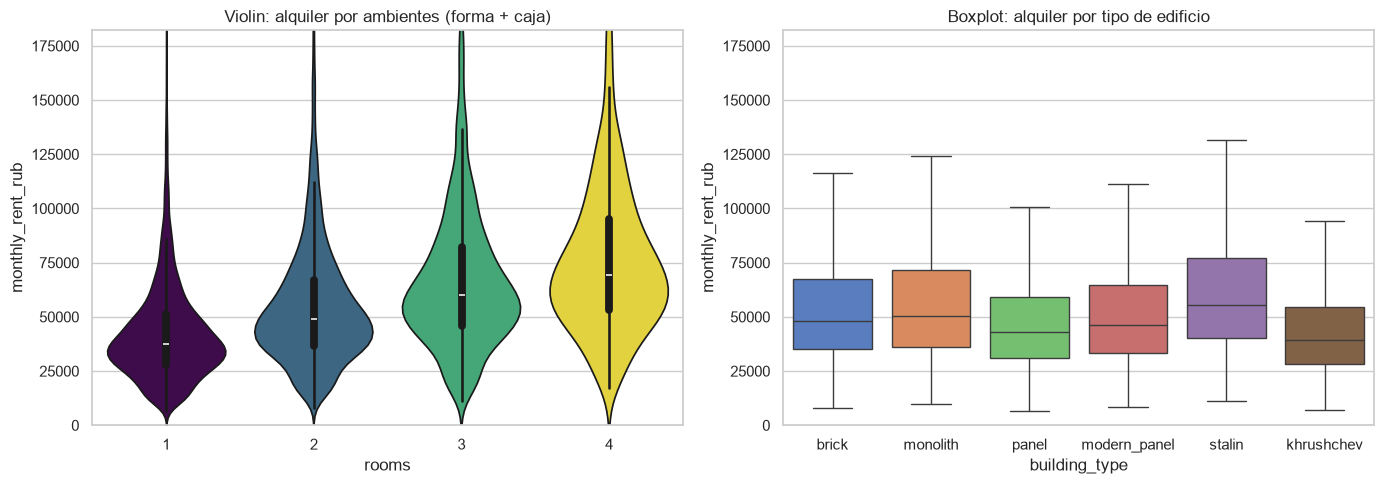

Eje Y limitado a p99.5 = 182,100 solo para visualizar; el analisis usa todos los datos.


In [84]:
cap = rentals[TARGET].quantile(0.995)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.violinplot(data=rentals, x="rooms", y=TARGET, ax=axes[0], inner="box",
               hue="rooms", palette="viridis", legend=False)
axes[0].set_ylim(0, cap)
axes[0].set_title("Violin: alquiler por ambientes (forma + caja)")
sns.boxplot(data=rentals, x="building_type", y=TARGET, ax=axes[1],
            showfliers=False, hue="building_type", palette="muted",
            legend=False)
axes[1].set_ylim(0, cap)
axes[1].set_title("Boxplot: alquiler por tipo de edificio")
plt.tight_layout()
plt.show()
print(f"Eje Y limitado a p99.5 = {cap:,.0f} solo para visualizar; "
      "el analisis usa todos los datos.")

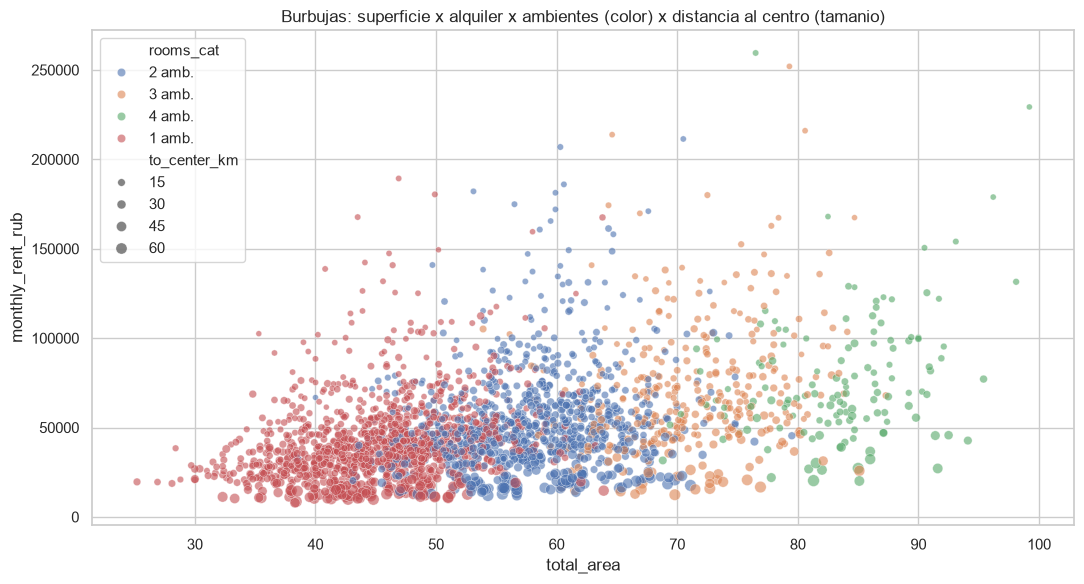

In [85]:
bub = rentals.sample(min(2500, len(rentals)), random_state=42).copy()
bub["rooms_cat"] = (pd.to_numeric(bub["rooms"], errors="coerce")
                    .round(0).astype("Int64").astype(str) + " amb.")
fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=bub, x="total_area", y=TARGET, hue="rooms_cat",
                size="to_center_km", alpha=0.6, ax=ax)
ax.set_title("Burbujas: superficie x alquiler x ambientes (color) "
             "x distancia al centro (tamanio)")
plt.tight_layout()
plt.show()

### A.7 Correlacion y colinealidad

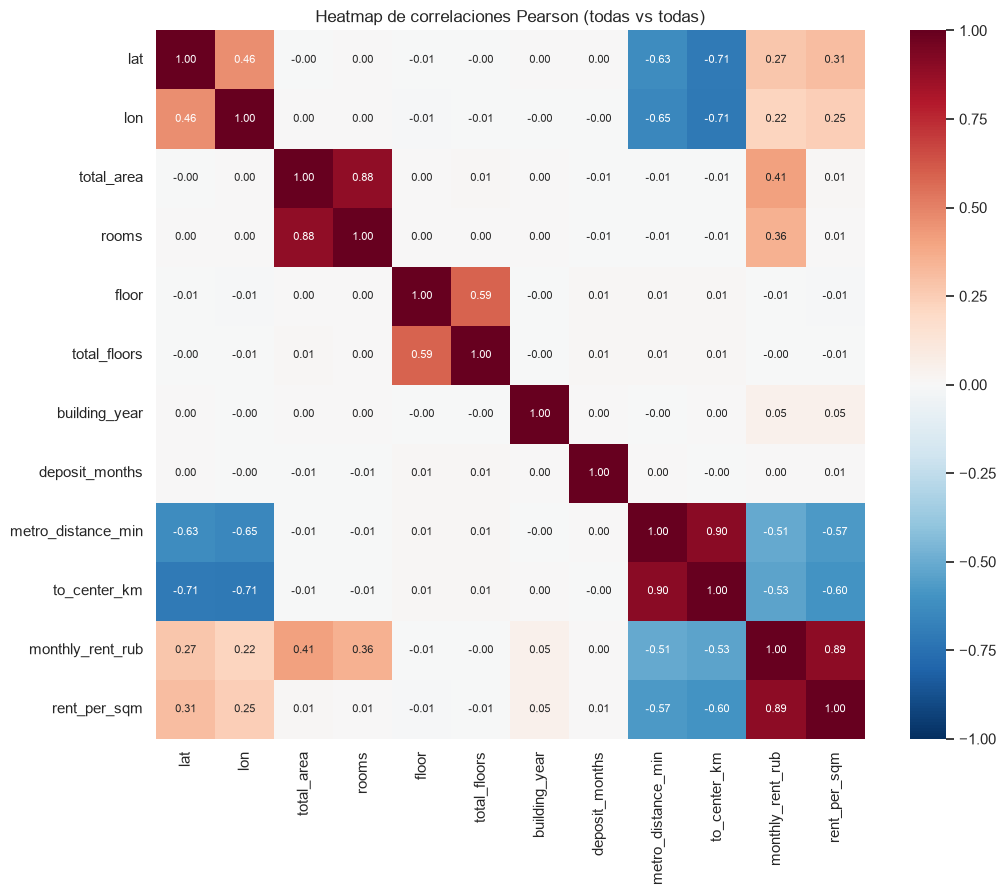

In [86]:
corr = num.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=ax,
            annot_kws={"size": 8})
ax.set_title("Heatmap de correlaciones Pearson (todas vs todas)")
plt.tight_layout()
plt.show()

In [87]:
tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
st = tri.stack().dropna()
pairs = pd.DataFrame({"r": st, "abs_r": st.abs()}).round(3)
pairs = pairs.sort_values("abs_r", ascending=False)
print("--- Top 15 pares por |r| (colinealidad candidata) ---")
display(pairs.head(15))
st_t = corr[TARGET].drop(TARGET).dropna()
tcorr = pd.DataFrame({"r": st_t, "abs_r": st_t.abs()}).round(3)
tcorr = tcorr.sort_values("abs_r", ascending=False)
print(f"--- Correlacion con {TARGET} ---")
display(tcorr)

--- Top 15 pares por |r| (colinealidad candidata) ---


,,r,abs_r
metro_distance_min,to_center_km,0.904,0.904
monthly_rent_rub,rent_per_sqm,0.893,0.893
total_area,rooms,0.883,0.883
lon,to_center_km,-0.713,0.713
lat,to_center_km,-0.706,0.706
lon,metro_distance_min,-0.652,0.652
lat,metro_distance_min,-0.628,0.628
to_center_km,rent_per_sqm,-0.596,0.596
floor,total_floors,0.594,0.594
metro_distance_min,rent_per_sqm,-0.574,0.574


--- Correlacion con monthly_rent_rub ---


,r,abs_r
rent_per_sqm,0.893,0.893
to_center_km,-0.531,0.531
metro_distance_min,-0.512,0.512
total_area,0.411,0.411
rooms,0.358,0.358
lat,0.274,0.274
lon,0.222,0.222
building_year,0.050,0.050
floor,-0.006,0.006
total_floors,-0.002,0.002


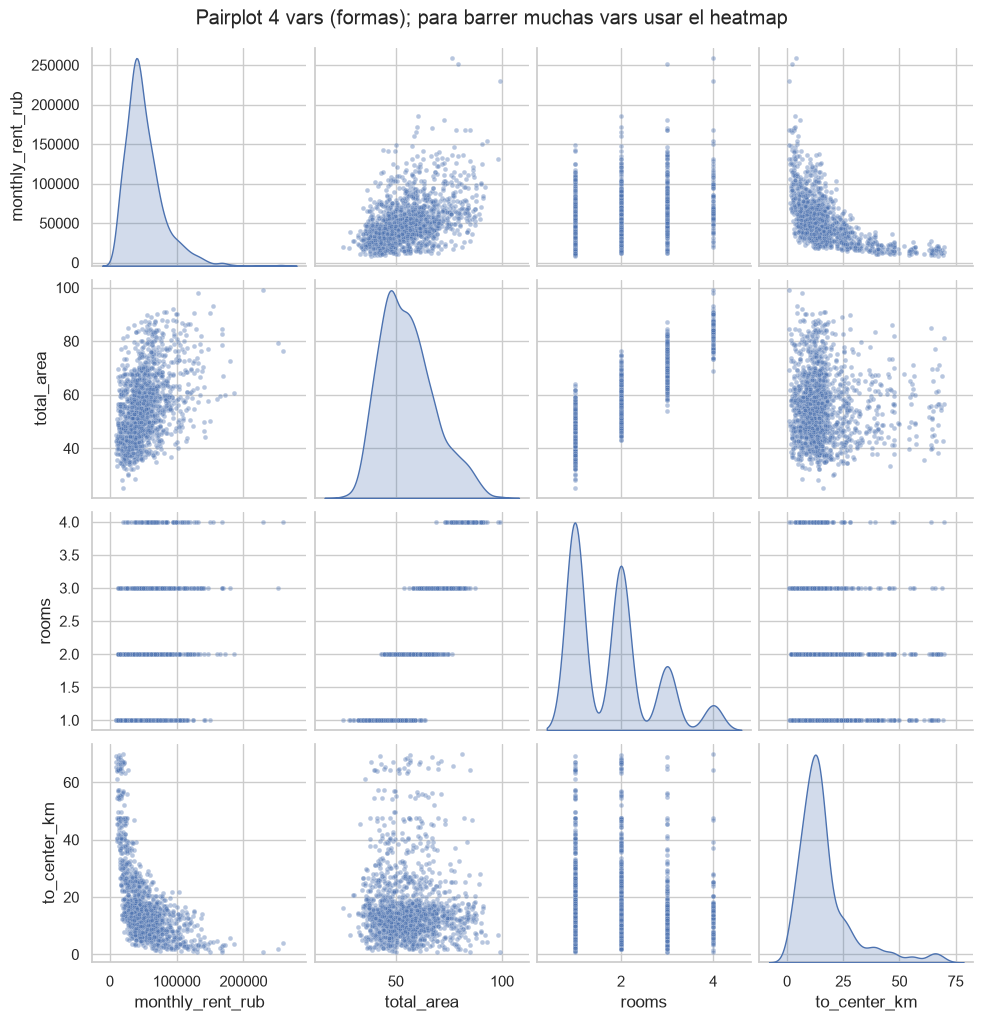

In [88]:
pp_vars = [TARGET, "total_area", "rooms", "to_center_km"]
g = sns.pairplot(rentals.sample(min(1500, len(rentals)),
                                random_state=42)[pp_vars],
                 diag_kind="kde", plot_kws={"alpha": 0.4, "s": 12})
g.fig.suptitle("Pairplot 4 vars (formas); para barrer muchas vars "
               "usar el heatmap", y=1.02)
plt.show()

### A.8 Normalidad: skew scoring

,var,skew,kurtosis,JB,p_JB
0,monthly_rent_rub,1.820,5.563,36832.8,0.00e+00
1,rent_per_sqm,1.593,4.019,21921.0,0.00e+00
2,total_area,0.576,-0.087,1114.2,1.16e-242
3,to_center_km,2.121,4.826,34404.1,0.00e+00
4,metro_distance_min,1.963,4.038,26428.0,0.00e+00
5,log_rent,-0.136,0.216,100.1,1.81e-22


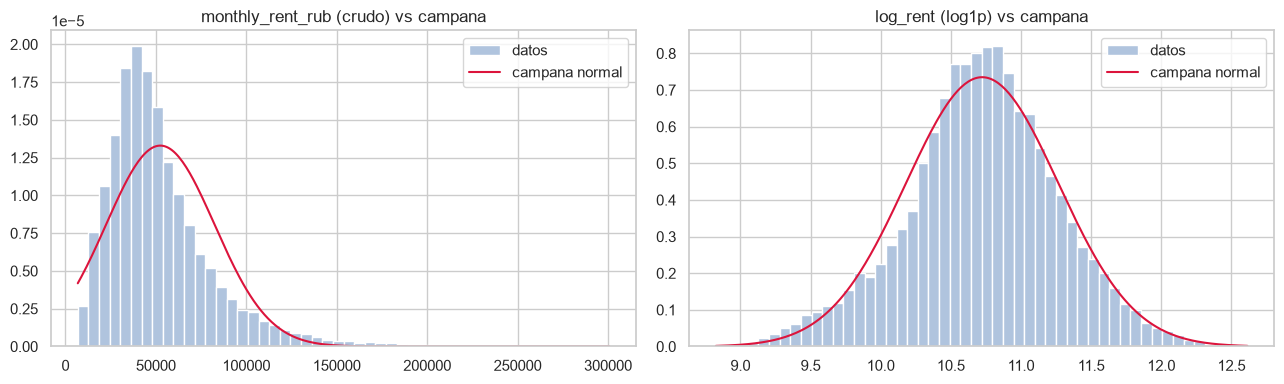

Con n aprox 20k cualquier micro-desvio rechaza JB (p aprox 0): el grafico manda, el test obedece.


In [89]:
NORM_VARS = [TARGET, "rent_per_sqm", "total_area", "to_center_km",
             "metro_distance_min"]
rentals["log_rent"] = np.log1p(rentals[TARGET])
rows = []
for col in NORM_VARS + ["log_rent"]:
    x = rentals[col].dropna()
    jb = stats.jarque_bera(x)
    rows.append({"var": col,
                 "skew": round(float(stats.skew(x)), 3),
                 "kurtosis": round(float(stats.kurtosis(x)), 3),
                 "JB": round(float(jb.statistic), 1),
                 "p_JB": f"{float(jb.pvalue):.2e}"})
display(pd.DataFrame(rows))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, ttl in [(axes[0], TARGET, "crudo"),
                     (axes[1], "log_rent", "log1p")]:
    x = rentals[col]
    ax.hist(x, bins=50, density=True, color="lightsteelblue",
            edgecolor="white", label="datos")
    xs = np.linspace(x.min(), x.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), color="crimson",
            label="campana normal")
    ax.set_title(f"{col} ({ttl}) vs campana")
    ax.legend()
plt.tight_layout()
plt.show()
print("Con n aprox 20k cualquier micro-desvio rechaza JB (p aprox 0): "
      "el grafico manda, el test obedece.")

## Fase B — joins y analisis enriquecido

- rentals LEFT JOIN district_prices_monthly por (district, year_month).
- rentals LEFT JOIN metro_stations por estacion.
- Claves verificadas 100% compatibles; igual se diagnostica match rate.

In [90]:
monthly = pd.read_csv(DATA_DIR / "district_prices_monthly.csv")
metro = pd.read_csv(DATA_DIR / "metro_stations.csv")
print("monthly:", monthly.shape, "| rango:",
      monthly["year_month"].min(), "->", monthly["year_month"].max())
print("metro:", metro.shape)
n0 = len(rentals)
enr = rentals.merge(monthly, on=["district", "year_month"], how="left",
                    suffixes=("", "_distmes"), indicator="m1")
print(f"join mensual: {n0:,} -> {len(enr):,} filas | "
      f"match={(enr['m1'] == 'both').mean():.2%}")
enr = enr.drop(columns=["m1"])
enr = enr.merge(metro, left_on="metro_station", right_on="station_name",
                how="left", suffixes=("", "_metro"), indicator="m2")
print(f"join metro: match={(enr['m2'] == 'both').mean():.2%}")
enr = enr.drop(columns=["m2"])
new_cols = [c for c in enr.columns if c not in rentals.columns]
print(f"columnas nuevas ({len(new_cols)}): {new_cols}")

monthly: (9804, 13) | rango: 2020-01 -> 2026-04
metro: (104, 6)
join mensual: 20,000 -> 20,000 filas | match=100.00%
join metro: match=100.00%
columnas nuevas (17): ['okrug_distmes', 'secondary_price_per_sqm', 'newbuild_price_per_sqm', 'rental_price_per_sqm_monthly', 'secondary_mom_change_pct', 'newbuild_mom_change_pct', 'n_listings_secondary', 'n_listings_newbuild', 'n_listings_rental', 'cbr_key_rate_pct', 'avg_mortgage_rate_pct', 'station_name', 'line', 'lat_metro', 'lon_metro', 'year_opened', 'to_center_km_metro']


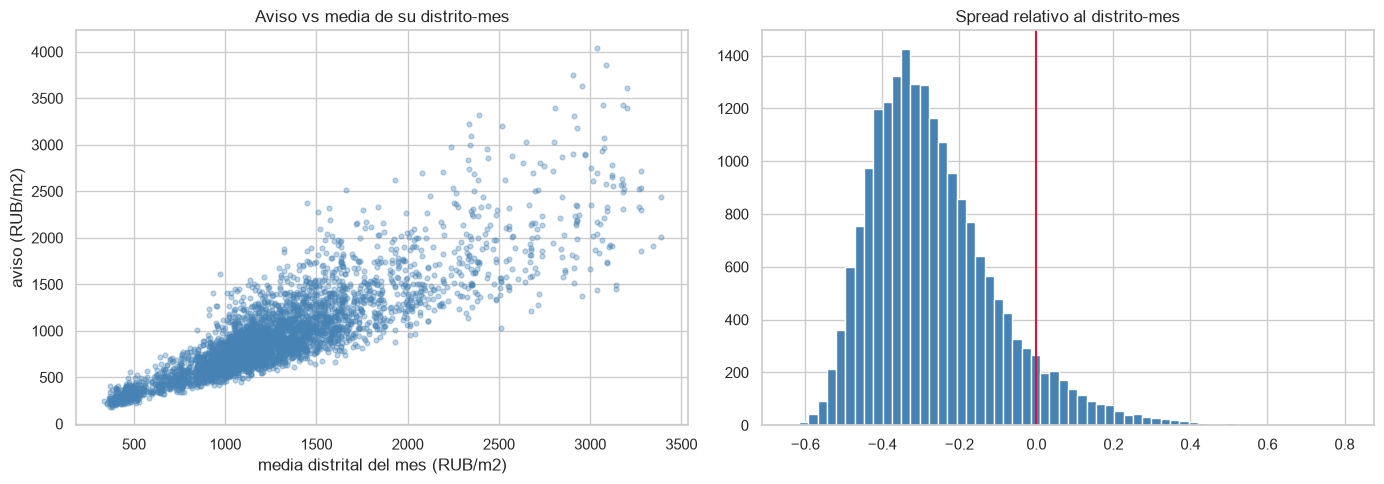

count    20000.000
mean        -0.265
std          0.168
min         -0.640
25%         -0.384
50%         -0.294
75%         -0.178
max          0.804
Name: spread_dist, dtype: float64


In [91]:
enr["spread_dist"] = ((enr["rent_per_sqm"]
                           - enr["rental_price_per_sqm_monthly"])
                          / enr["rental_price_per_sqm_monthly"])
s2 = enr.sample(min(4000, len(enr)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(s2["rental_price_per_sqm_monthly"], s2["rent_per_sqm"],
                alpha=0.35, s=12, color="steelblue")
axes[0].set_xlabel("media distrital del mes (RUB/m2)")
axes[0].set_ylabel("aviso (RUB/m2)")
axes[0].set_title("Aviso vs media de su distrito-mes")
enr["spread_dist"].hist(bins=60, ax=axes[1], color="steelblue",
                        edgecolor="white")
axes[1].axvline(0, color="crimson")
axes[1].set_title("Spread relativo al distrito-mes")
plt.tight_layout()
plt.show()
print(enr["spread_dist"].describe().round(3))

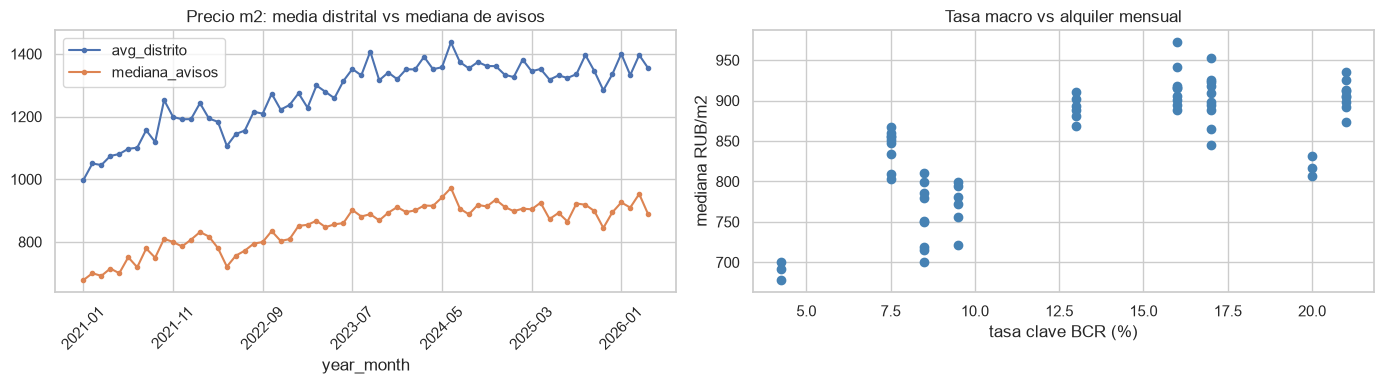

In [92]:
mes = enr.groupby("year_month").agg(
    avg_distrito=("rental_price_per_sqm_monthly", "mean"),
    mediana_avisos=("rent_per_sqm", "median"),
    cbr=("cbr_key_rate_pct", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
mes[["avg_distrito", "mediana_avisos"]].plot(ax=axes[0], marker="o",
                                             markersize=3)
axes[0].set_title("Precio m2: media distrital vs mediana de avisos")
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45)
axes[1].scatter(mes["cbr"], mes["mediana_avisos"], color="steelblue")
axes[1].set_xlabel("tasa clave BCR (%)")
axes[1].set_ylabel("mediana RUB/m2")
axes[1].set_title("Tasa macro vs alquiler mensual")
plt.tight_layout()
plt.show()

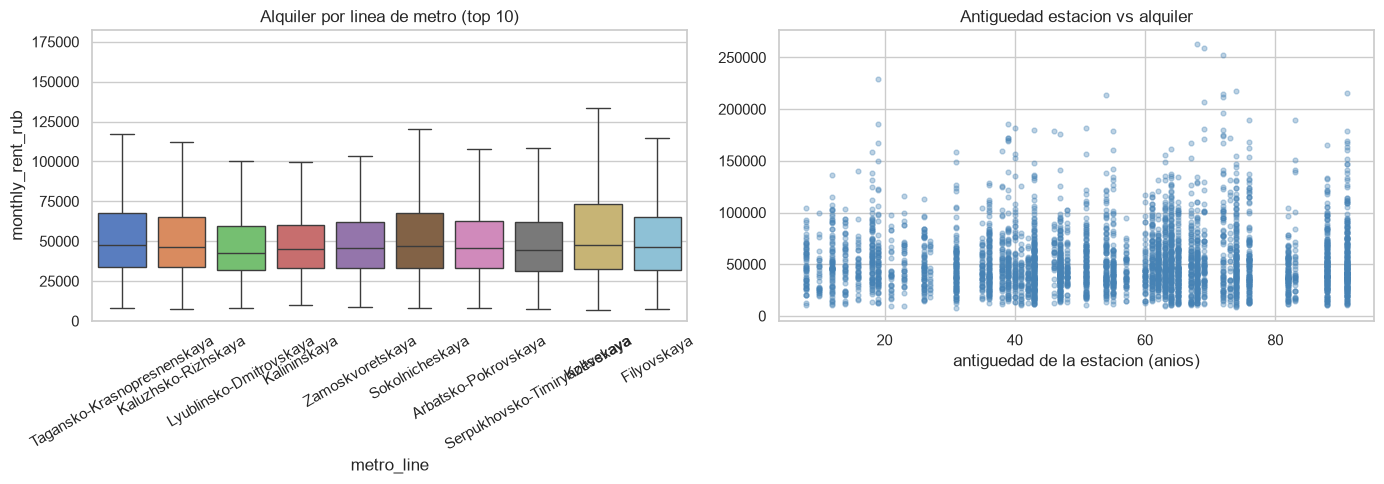

In [93]:
top_lines = enr["metro_line"].value_counts().head(10).index
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=enr[enr["metro_line"].isin(top_lines)], x="metro_line",
            y=TARGET, ax=axes[0], showfliers=False, hue="metro_line",
            legend=False, palette="muted")
axes[0].set_ylim(0, enr[TARGET].quantile(0.995))
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_title("Alquiler por linea de metro (top 10)")
enr["antiguedad_estacion"] = 2026 - enr["year_opened"]
s3 = enr.sample(min(4000, len(enr)), random_state=42)
axes[1].scatter(s3["antiguedad_estacion"], s3[TARGET], alpha=0.35, s=12,
                color="steelblue")
axes[1].set_xlabel("antiguedad de la estacion (anios)")
axes[1].set_title("Antiguedad estacion vs alquiler")
plt.tight_layout()
plt.show()

## Contexto ventas (agregados distritales)

Las filas de `secondary_market.csv` y `new_builds.csv` pertenecen al objetivo
de venta; aca solo se usan sus agregados del mensual (price-to-rent).

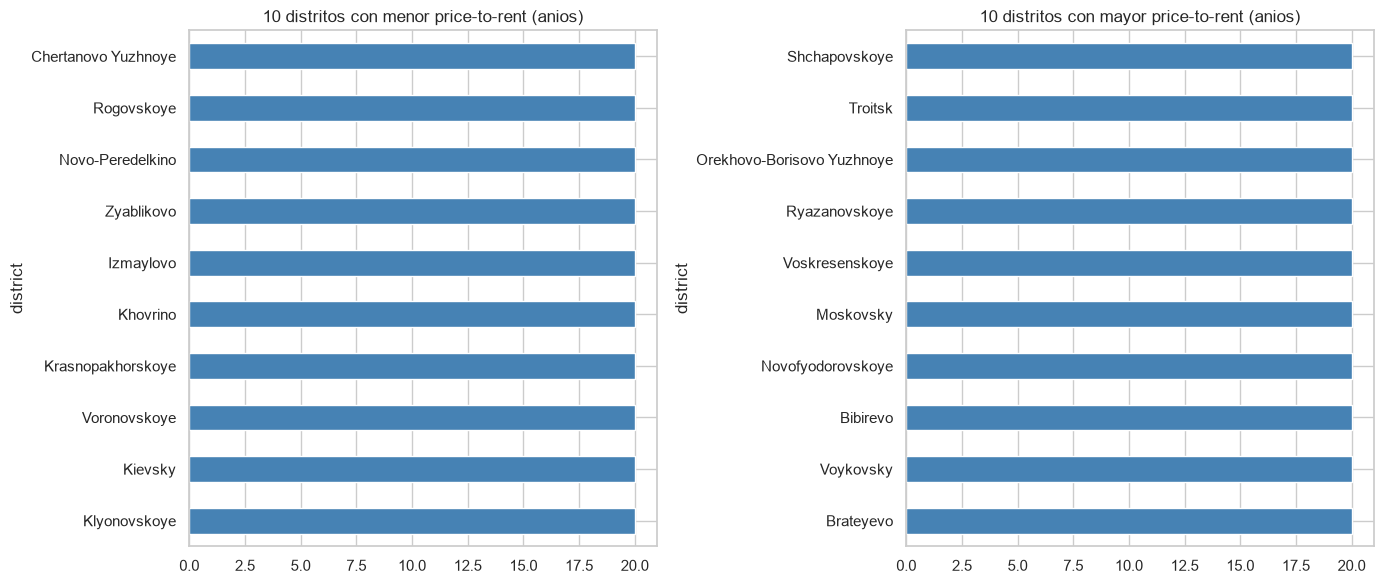

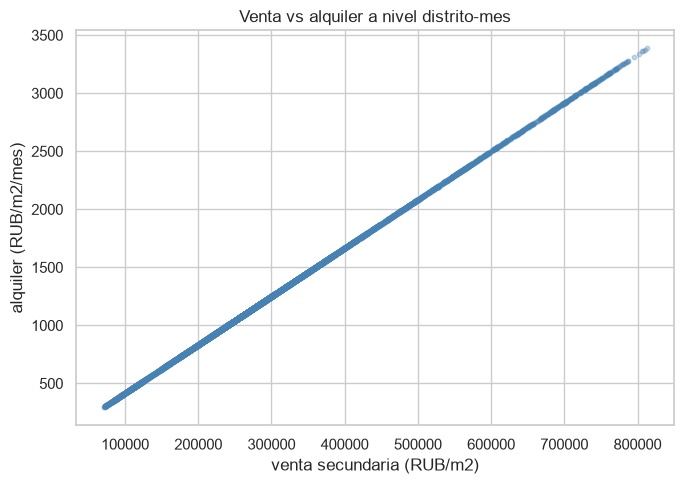

In [94]:
ctx = monthly.copy()
ctx["price_to_rent_anios"] = (ctx["secondary_price_per_sqm"]
                              / (ctx["rental_price_per_sqm_monthly"] * 12))
por_dist = ctx.groupby("district")["price_to_rent_anios"].median()
por_dist = por_dist.sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
por_dist.head(10).sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("10 distritos con menor price-to-rent (anios)")
por_dist.tail(10).sort_values().plot.barh(ax=axes[1], color="steelblue")
axes[1].set_title("10 distritos con mayor price-to-rent (anios)")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(ctx["secondary_price_per_sqm"],
           ctx["rental_price_per_sqm_monthly"],
           alpha=0.3, s=10, color="steelblue")
ax.set_xlabel("venta secundaria (RUB/m2)")
ax.set_ylabel("alquiler (RUB/m2/mes)")
ax.set_title("Venta vs alquiler a nivel distrito-mes")
plt.tight_layout()
plt.show()

## Notas para continuar

Hallazgos y decisiones para el modelo (ver detalle en
`alquiler/objetivo_branch.md`):

- Calidad: 20.000 filas, 0 nulos, 0 duplicados.
- Target muy sesgado (skew 1,82); log1p lo deja simetrico (-0,14):
  modelar en log.
- `rent_per_sqm` (r=0,89) deriva del target: excluirla como feature (fuga).
- Colinealidad fuerte: metro_distance_min<->to_center_km (0,90),
  total_area<->rooms (0,88): no usar ambas sin seleccionar/regularizar.
- Seniales top: to_center_km (-0,53), metro_distance_min (-0,51),
  total_area (0,41), rooms (0,36); floor/pisos/deposito aprox 0.
- Gradientes: CAO ~110k vs TAO ~18k; 4 amb ~78k vs 1 amb ~42k;
  designer > euro > cosmetic > no_renovation.
- Joins Fase B al 100% (20.000 filas intactas, +17 columnas de contexto).